# 9月经营分析V1
**基于模拟数据的业务分析项目。** 先运行01_data_cleaning_v1.ipynb或scripts/run_project_v1.py生成成果。本Notebook逐段展示收入→利润→维度→证据→建议。

In [1]:
from pathlib import Path
import sys
import pandas as pd
ROOT = Path.cwd()
if not (ROOT / 'data/raw').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data/raw/orders.csv').exists()
sys.path.insert(0, str(ROOT / 'scripts'))
pd.set_option('display.max_columns', 20)

T = ROOT / "reports/tables"

## 销售额口径敏感性
读取不同样本的月度销售额。raw含重复且存在异常，不能直接当最终收入。临时有效销售含未知成本商品；利润样本额外排除未知成本。

In [2]:
sensitivity = pd.read_csv(T / "sales_sensitivity.csv")
sensitivity

,month,raw_sales,deduplicated_with_flags,temporary_valid_sales,known_cost_sales
0,2026-08,209693.41,209404.22,167440.02,167384.39
1,2026-09,146026.22,145756.06,135765.53,135697.67


## 月度利润账
`pct_change()`输入按月排序指标，输出环比。经营贡献利润扣商品、履约、佣金、批准确认退款及已记录广告；不含工资税费。

In [3]:
monthly = pd.read_csv(T / "monthly_profit.csv").set_index("month")
display(monthly.round(2))
monthly[["sales","gross_profit","contribution"]].pct_change().mul(100).round(2)

,sales,goods_cost,gross_profit,shipping_cost,platform_cost,before_refunds_ads,units,completed_orders,refund_cost,recorded_ad_cost,contribution,gross_margin_pct
month,,,,,,,,,,,,
2026-08,167384.39,67851.0,99533.39,17100.6,16306.15,66126.64,5946,5125,2528.02,12616.83,50981.79,59.46
2026-09,135697.67,57774.0,77923.67,14674.0,12927.04,50322.63,5113,4426,4508.31,15364.66,30449.66,57.42


,sales,gross_profit,contribution
month,,,
2026-08,NaN,NaN,NaN
2026-09,-18.93,-21.71,-40.27


## SQL独立复核
SQLite连接派生数据库，SQL用CTE先聚合再关联费用避免多对多。输出与Pandas逐月金额核对，不依赖Notebook隐藏状态。

In [4]:
import sqlite3
with sqlite3.connect(ROOT / "data/processed/business_analysis.sqlite") as conn:
    sql = (ROOT / "sql/01_monthly_profit.sql").read_text(encoding="utf-8")
    sql_result = pd.read_sql_query(sql, conn).set_index("month")
assert (sql_result.contribution - monthly.contribution).abs().max() < 0.000001
sql_result.round(2)

,sales,goods_cost,refund_cost,recorded_ad_cost,contribution
month,,,,,
2026-08,167384.39,67851.0,2528.02,12616.83,50981.79
2026-09,135697.67,57774.0,4508.31,15364.66,30449.66


## 精确对账桥梁与毛利结构
桥梁正数推动利润下降；毛利分解正数推动毛利增长。SKU内平均标价变化同时受国家渠道结构影响，不等同实际调价。

In [5]:
display(pd.read_csv(T / "profit_bridge.csv"))
display(pd.read_csv(T / "gross_profit_decomposition.csv"))

,factor,profit_decline_impact
0,销售额减少,31686.72
1,商品成本变化,-10077.00
2,物流费变化,-2426.60
3,平台佣金变化,-3379.11
4,退款增加,1980.29
5,已记录广告费增加,2747.83


,factor,gross_profit_change
0,总销量变化,-14886.145693
1,SKU销量结构变化,-1971.446781
2,SKU内标价/国家渠道结构变化,-389.487526
3,单位采购成本变化,0.000000
4,优惠总额变化,-4362.640000


## 平台和SKU定位
两个维度解释同一利润，不能相加。退款按原订单归维度，按确认日期归期间。

In [6]:
display(pd.read_csv(T / "platform_changes.csv"))
display(pd.read_csv(T / "sku_changes.csv"))

,platform_standard,sales_change,gross_profit_change,contribution_change
0,Amazon,-15638.91,-9783.91,-5213.81
1,TikTok Shop,-12461.24,-9752.24,-13546.85
2,Shopee,-3586.57,-2073.57,-1771.47


,sku_standard,sales_change,gross_profit_change,contribution_change
0,SKU001,-17262.14,-11256.14,-8162.48
1,SKU005,-2976.96,-2016.96,-1586.74
2,SKU010,-2087.43,-1365.43,-1348.19
3,SKU002,-2020.89,-1613.89,-1406.13
4,SKU009,-1564.23,-1044.23,-986.02
5,SKU011,-1278.17,-828.17,-897.92
6,SKU008,-1175.00,-759.00,-646.92
7,SKU012,-1058.88,-658.88,-617.95
8,SKU007,-1023.43,-753.43,-640.45
9,SKU004,-998.98,-893.98,-3032.31


## 库存、优惠、广告及售后证据
情景估算固定指定规模并假设参考期可比，不是独立因果贡献；ROAS用广告同一已知花费样本。退款按下单月统一12天窗口。

In [7]:
display(pd.read_csv(T / "scenarios.csv"))
display(pd.read_csv(T / "advertising_efficiency.csv"))
cohorts = pd.read_csv(T / "refund_cohorts_12d.csv")
cohorts.loc[cohorts.sku_standard == "SKU004"]

,scenario,amount,assumption
0,SKU001四日零库存潜在销售额,5075.885714,需求和平均实收与附近14个有货日相近；不含17日；非实际损失
1,TK优惠加深固定9月销售结构,5209.292385,固定9月销量及标价，沿用8月优惠率；非可追回利润
2,TK点击变贵固定9月点击数,4088.978022,沿用8月平均CPC，包含广告组合变化；非可直接节省额


,platform_standard,month,spend,clicks,revenue,conversions,cpc,roas
0,Amazon,2026-08,5815.30,13847,21379.23,617,0.419968,3.676376
1,Amazon,2026-09,4636.32,11017,15200.80,442,0.420833,3.278635
2,Shopee,2026-08,1743.95,10337,11697.10,404,0.168709,6.707245
3,Shopee,2026-09,1752.60,10345,10239.67,355,0.169415,5.842560
4,TikTok Shop,2026-08,5057.58,14804,24605.83,706,0.341636,4.865139
5,TikTok Shop,2026-09,8975.74,14304,20619.03,670,0.627499,2.297196


,sku_standard,month,orders,refunded_orders,refund_rate_pct
6,SKU004,2026-08,423,14,3.309693
7,SKU004,2026-09,408,71,17.401961


## 国家与品类结构
国家只比较销售和毛利，不随意分摊广告来制造国家净利润。

In [8]:
display(pd.read_csv(T / "country_changes.csv"))
display(pd.read_csv(T / "category_mix.csv"))

,country_standard,sales_change,gross_profit_change
0,GB,-12258.12,-8559.12
1,US,-10196.70,-7375.70
2,DE,-5645.33,-3601.33
3,SG,-1265.81,-779.81
4,MY,-1168.36,-690.36
5,PH,-1152.40,-603.40


,category,month,sales,units,gross_profit,sales_share_pct
0,宠物用品,2026-08,4431.80,295,2661.80,2.647678
1,宠物用品,2026-09,3737.35,256,2201.35,2.754174
2,家居用品,2026-08,14117.94,534,8777.94,8.434442
3,家居用品,2026-09,11140.98,438,6760.98,8.210148
4,小家电,2026-08,57545.96,1661,35551.96,34.379526
5,小家电,2026-09,38719.59,1180,23251.59,28.533718
6,数码配件,2026-08,68657.99,2246,39311.99,41.018156
7,数码配件,2026-09,61468.38,2072,34026.38,45.298036
8,旅行用品,2026-08,16057.49,863,9432.49,9.593182
9,旅行用品,2026-09,15233.16,872,8645.16,11.225808


## 图表与报告
输入已核验汇总，显示静态图；完整离线交互图在dashboard/index.html。行动建议未实施，不声称实际收益。

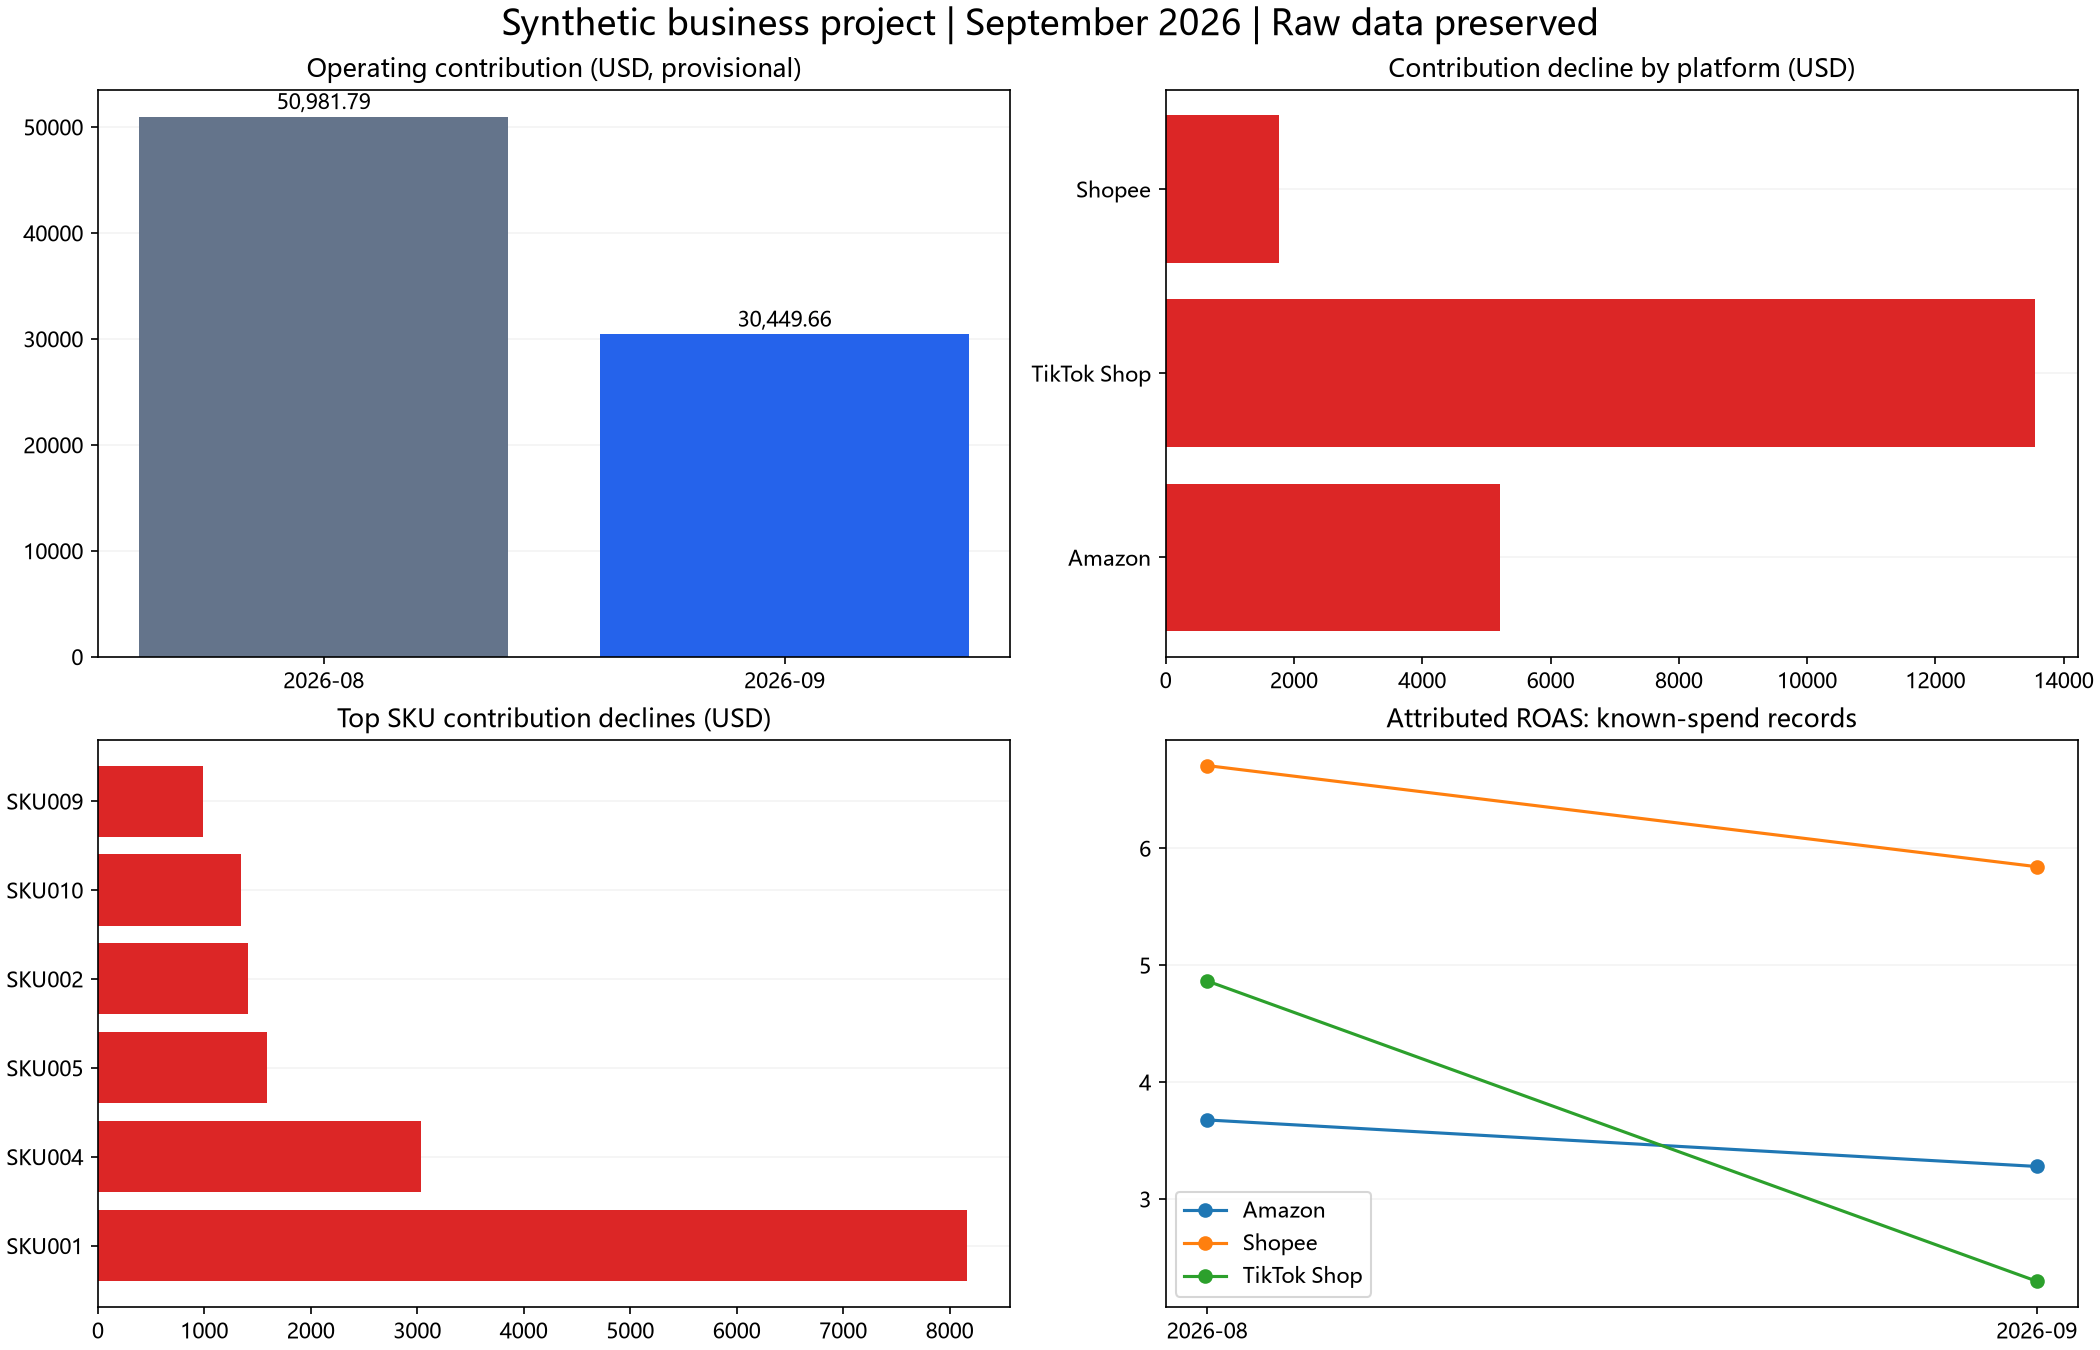

In [9]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "dashboard/overview.png")))

## 自动化与AI
运行weekly_report.py生成7天经营周报、证据包和AI提示词。AI草稿仅引用白名单指标，程序渲染数字并验证；业务因果仍人工核查。
完整报告：reports/september_business_report.md；口径：docs/methodology.md；求职材料：docs/resume_project_description.md。